# 03 · Comparação com árvores clássicas

Reprodução da Tabela 1 do artigo, com algumas coisas a mais:

- **5 sementes** por tamanho (média ± desvio), já que diferenças de 1–2 pontos não dizem nada sem variância
- split **70/30 estratificado**, com o pré-processamento ajustado só no treino
- além de acurácia: **precisão, recall e F1** (a classe positiva é "ataque")
- **duas ablações** pra isolar o efeito da parte quântica:
  - **só IG (alpha=1)**: a mesma árvore com os mesmos limiares por percentil, mas sem distância nenhuma
  - **distância RBF**: troca a fidelidade quântica por um kernel clássico $e^{-\gamma\|x-y\|^2}$
- teste no **KDDTest+** oficial

Modelos (todos com 3 componentes do PCA):

In [1]:
import sys
sys.path.insert(0, "../src")  # pra importar o pacote hqdt sem instalar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# paleta categórica validada (daltonismo) + estilo discreto
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 8, "figure.dpi": 110,
})

In [2]:
from hqdt.experiments import get_models, run_sizes, run_official_test, summarize
list(get_models())

['Árvore clássica (sem limite)',
 'Árvore clássica (depth=4)',
 'HQDT quântica (depth=4, alpha=0.5)',
 'Ablação: só IG, percentis (depth=4, alpha=1)',
 'Ablação: distância RBF clássica (depth=4, alpha=0.5)']

## 1. Acurácia por tamanho de amostra

Leva uns 30 segundos.

In [3]:
df = run_sizes(sizes=(1000, 5000, 10000, 25000), seeds=(0, 1, 2, 3, 4), verbose=False)
df.to_csv("../results/resultados_tamanhos.csv", index=False)
summarize(df, "accuracy")

n,1000,5000,10000,25000
modelo,,,,
"Ablação: distância RBF clássica (depth=4, alpha=0.5)",90.5 ± 0.9,90.4 ± 1.1,90.5 ± 0.9,90.6 ± 0.3
"Ablação: só IG, percentis (depth=4, alpha=1)",92.1 ± 1.0,93.7 ± 0.9,93.5 ± 0.7,93.4 ± 0.5
"HQDT quântica (depth=4, alpha=0.5)",91.7 ± 1.4,90.0 ± 0.7,92.1 ± 0.7,90.8 ± 1.3
Árvore clássica (depth=4),92.3 ± 1.0,94.0 ± 1.2,94.6 ± 0.8,94.8 ± 0.3
Árvore clássica (sem limite),92.8 ± 1.1,95.5 ± 0.3,96.6 ± 0.4,97.2 ± 0.2


Pra comparar, a Tabela 1 do artigo:

| Modelo | 1.000 | 5.000 | 10.000 | 25.000 |
|---|---|---|---|---|
| Árvore clássica (sem limite) | 89,4% | 91,2% | 92,1% | 93,5% |
| Árvore clássica (depth=4) | 84,1% | 85,5% | 86,2% | 86,9% |
| HQDT (depth=4) | 91,8% | 93,2% | 94,5% | 95,1% |

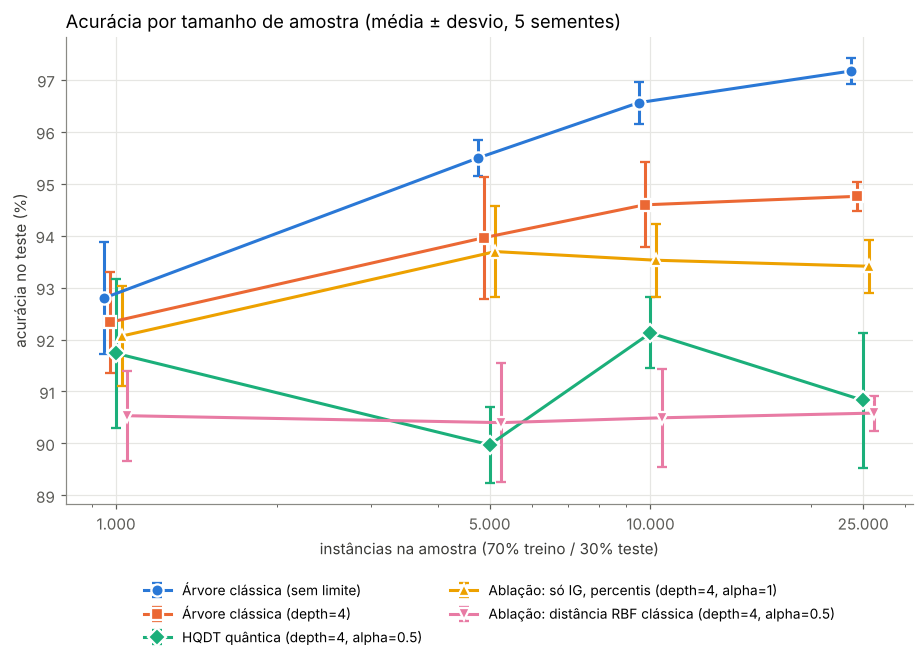

In [4]:
ordem = list(get_models())
fig, ax = plt.subplots(figsize=(8.5, 6.2))
marcadores = ["o", "s", "D", "^", "v"]
for i, nome in enumerate(ordem):
    g = df[df["modelo"] == nome].groupby("n")["accuracy"]
    m, s = g.mean() * 100, g.std() * 100
    x = m.index * (1 + 0.025 * (i - 2))  # desloca um pouco pra barras não se sobreporem
    ax.errorbar(x, m.values, yerr=s.values, color=CORES[i], marker=marcadores[i],
                capsize=3, label=nome, markeredgecolor="white", markeredgewidth=1.5)
ax.set_xscale("log")
ax.set_xticks([1000, 5000, 10000, 25000], ["1.000", "5.000", "10.000", "25.000"])
ax.set_xlabel("instâncias na amostra (70% treino / 30% teste)")
ax.set_ylabel("acurácia no teste (%)")
ax.set_title("Acurácia por tamanho de amostra (média ± desvio, 5 sementes)", loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
plt.tight_layout()
plt.savefig("../results/acuracia_por_tamanho.png", dpi=150)
plt.show()

## 2. Precisão, recall e F1 (25.000 instâncias)

In [5]:
(df[df["n"] == 25000].groupby("modelo")[["accuracy", "precision", "recall", "f1", "depth", "folhas", "fit_time_s"]]
   .mean().reindex(ordem).round(3))

,accuracy,precision,recall,f1,depth,folhas,fit_time_s
modelo,,,,,,,
Árvore clássica (sem limite),0.972,0.967,0.972,0.970,21.4,399.8,0.047
Árvore clássica (depth=4),0.948,0.987,0.899,0.941,4.0,14.8,0.024
"HQDT quântica (depth=4, alpha=0.5)",0.908,0.978,0.824,0.893,4.0,8.8,0.511
"Ablação: só IG, percentis (depth=4, alpha=1)",0.934,0.980,0.876,0.925,4.0,14.2,0.026
"Ablação: distância RBF clássica (depth=4, alpha=0.5)",0.906,0.903,0.896,0.898,4.0,13.0,0.048


## 3. Teste no KDDTest+ oficial

Treino em 25.000 instâncias do KDDTrain+ e teste nas 22.544 do KDDTest+ (3 sementes). Esse teste é bem mais difícil porque tem tipos de ataque que não aparecem no treino.

In [6]:
off = run_official_test(n_train=25000, seeds=(0, 1, 2))
off.to_csv("../results/resultados_kddtest.csv", index=False)
g = off.groupby("modelo")[["accuracy", "precision", "recall", "f1"]]
(g.mean().reindex(ordem) * 100).round(1).astype(str) + " ± " + (g.std().reindex(ordem) * 100).round(1).astype(str)

,accuracy,precision,recall,f1
modelo,,,,
Árvore clássica (sem limite),76.1 ± 1.2,91.9 ± 0.4,63.5 ± 2.0,75.1 ± 1.6
Árvore clássica (depth=4),73.3 ± 0.4,93.3 ± 0.2,57.2 ± 0.6,70.9 ± 0.5
"HQDT quântica (depth=4, alpha=0.5)",71.3 ± 2.2,98.1 ± 2.0,50.6 ± 5.2,66.7 ± 3.9
"Ablação: só IG, percentis (depth=4, alpha=1)",73.8 ± 0.3,95.9 ± 2.9,56.5 ± 1.7,71.0 ± 0.6
"Ablação: distância RBF clássica (depth=4, alpha=0.5)",76.6 ± 0.5,91.5 ± 1.4,64.9 ± 0.2,75.9 ± 0.3


## 4. Sensibilidade a alpha e às repetições do feature map

O artigo usa só alpha = 0.5 e não diz o `reps` do ZZFeatureMap. Aqui a gente varre os dois (25.000 instâncias, 3 sementes). alpha = 1 é a árvore só com IG.

In [7]:
from hqdt import HybridQuantumDecisionTree, make_split

rows = []
for seed in range(3):
    X_tr, X_te, y_tr, y_te = make_split(25000, seed=seed)
    for reps in (1, 2):
        for alpha in (0.0, 0.25, 0.5, 0.75, 0.9, 1.0):
            m = HybridQuantumDecisionTree(4, alpha=alpha, reps=reps, distance="quantum").fit(X_tr, y_tr)
            rows.append({"seed": seed, "reps": reps, "alpha": alpha, "accuracy": m.score(X_te, y_te)})
sweep = pd.DataFrame(rows)
sweep.to_csv("../results/sweep_alpha_reps.csv", index=False)
(sweep.groupby(["alpha", "reps"])["accuracy"].mean().unstack("reps") * 100).round(1).add_prefix("reps=")

reps,reps=1,reps=2
alpha,,
0.00,88.3,88.0
0.25,89.8,90.8
0.50,90.9,92.3
0.75,93.6,93.3
0.90,93.5,93.3
1.00,93.1,93.1


## 5. Conclusões

Os números abaixo são os desta execução (sementes fixas, então rodar de novo dá o mesmo resultado).

**1. A reprodução não confirma a Tabela 1 do artigo.** Com 25.000 instâncias, a árvore clássica com depth=4 chega a **~94,8%**, e não 86,9%. A HQDT com alpha=0.5 fica em **~90,8%**, e não 95,1%. Ou seja, nesse protocolo **a HQDT fica abaixo da árvore clássica de mesma profundidade**.

**2. A ablação mostra de onde vem cada efeito.** A árvore "só IG + percentis" (alpha=1) chega a ~93,4%. A diferença pro scikit-learn (~94,8%) vem de testar só 4 limiares por feature em vez de todos. Somar a distância com alpha=0.5 **piora** o resultado. Com alpha=0.75 a parte quântica dá um ganho pequeno sobre o "só IG" (~93,6% contra ~93,1%, com 3 sementes), mas ainda não supera o scikit-learn.

**3. A distância RBF clássica funciona parecido com a quântica.** Isso indica que o efeito vem de "usar uma distância", não de algo especificamente quântico.

**4. O cache de fidelidade não é usado.** Ele teve 0 acertos em todas as execuções (notebook 02), então não pode ser a causa da redução de tempo descrita no artigo. O que reduz o custo de verdade é limitar os candidatos a 4 percentis e usar a média da partição em vez de pares de pontos.

**5. No KDDTest+ oficial todos os modelos caem pra 71–77%,** por causa dos ataques que não aparecem no treino e da compressão pra 3 componentes. A HQDT é a pior (71,3% ± 2,2) e a que mais varia. A precisão dela é altíssima (~98%), mas ela deixa passar metade dos ataques (recall ~51%).

**6. O ponto a favor: árvores mais enxutas.** Com 25.000 instâncias, a HQDT termina com ~8,8 folhas, contra ~14,8 da árvore do scikit-learn com depth=4. Isso confirma a afirmação do artigo de que ela gera árvores mais compactas, mas aqui isso vem com perda de acurácia.

### Por que pode ter dado diferente do artigo
O artigo não informa o protocolo de treino/teste, o `reps` do feature map, nem como a baseline clássica foi implementada. Uma baseline depth=4 com 86,9% sugere que a árvore clássica do artigo foi treinada em outro setup (por exemplo, outro pré-processamento ou um split diferente). **Pra fechar essa conta é preciso o script original dos experimentos.**